# Hidden Value: Defensive Drive-Quality (mirror of Phase 4)

The exact same framework as the offensive analysis, pointed at the **defense**. Same drives, read from the other side: a drive the offense scored 7 on is a drive that defense *allowed* 7 on. So every metric is your offensive metric grouped by `defteam` instead of `posteam`, with the direction of "good" flipped (**fewer points allowed = better defense**).

Grounded in Design Doc v1.1. Same rules: garbage time and clock-expiration drives excluded, 40-drives-faced gate before rankings, everything stamped PREVIEW until then.

## 0. Load, build the analysis frame, and check the gate

In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size":13,"axes.titlesize":16,"axes.titleweight":"bold","figure.autolayout":True})

CSV = r"C:\Users\brade\OneDrive - Worcester Polytechnic Institute (wpi.edu)\Desktop\Football\hidden_value_2026_drives.csv"
drives = pd.read_csv(CSV)

# same primary frame as offense (Doc Sec 11 + 14)
a = drives[(drives["garbage_time"]==0) & (drives["clock_expiration"]==0)].copy()
a["success_rate"]   = a["success_plays"]/a["qualifying_plays"].replace(0,np.nan)
a["explosive_rate"] = a["explosive_plays"]/a["qualifying_plays"].replace(0,np.nan)

# GATE by DEFENSE: how many drives has each defense faced?
gate = drives[drives["garbage_time"]==0].groupby("defteam").size()
PREVIEW = gate.min() < 40
STAMP = "PREVIEW - not a finding" if PREVIEW else "FINDINGS (gate open)"
print("="*60)
print("STATUS:", STAMP)
print(f"drives analyzed: {len(a)} | defenses: {a['defteam'].nunique()}")
print(f"fewest drives faced by one defense: {gate.min()} (need 40 before rankings)")
print("="*60)

def std_betas(frame, y, xs):
    d = frame[[y]+xs].dropna()
    Z = (d - d.mean())/d.std(ddof=0)
    beta,*_ = np.linalg.lstsq(Z[xs].values, Z[y].values, rcond=None)
    return pd.Series(beta, index=xs).reindex(pd.Series(beta,index=xs).abs().sort_values(ascending=False).index)

def ols_predict(frame, y, xs):
    d = frame[[y]+xs].dropna().copy()
    X = np.column_stack([np.ones(len(d)), d[xs].values])
    coef,*_ = np.linalg.lstsq(X, d[y].values, rcond=None)
    d["pred"] = X @ coef
    return d

STATUS: PREVIEW - not a finding
drives analyzed: 1097 | defenses: 32
fewest drives faced by one defense: 24 (need 40 before rankings)


## 1. Defensive team table (everything "allowed")

One row per defense. Every column is what that defense gave up. `_allowed` = lower is better; `forced`/`sack` = higher is better.

In [8]:
g = a.groupby("defteam")
dm = pd.DataFrame({
    "drives_faced":            g.size(),
    "ppd_allowed":             g["offensive_points"].mean(),
    "success_rate_allowed":    g["success_plays"].sum()/g["qualifying_plays"].sum(),
    "explosive_rate_allowed":  g["explosive_plays"].sum()/g["qualifying_plays"].sum(),
    "rz_rate_allowed":         g["reached_20"].mean(),
    "avg_start_forced":        g["start_yardline_100"].mean(),   # higher = opponents start further back
    "to_forced_rate":          g["turnovers"].mean(),            # higher = more takeaways
    "sack_rate":               g["sacks"].sum()/g["qualifying_plays"].sum(),
})
if "third_down_attempts" in a.columns:
    dm["third_down_rate_allowed"] = g["third_down_conversions"].sum()/g["third_down_attempts"].sum().replace(0,np.nan)

print(f"[{STAMP}]  defenses sorted by fewest points allowed per drive:")
print(dm.sort_values("ppd_allowed").round(3).to_string())

[PREVIEW - not a finding]  defenses sorted by fewest points allowed per drive:
         drives_faced  ppd_allowed  success_rate_allowed  explosive_rate_allowed  rz_rate_allowed  avg_start_forced  to_forced_rate  sack_rate  third_down_rate_allowed
defteam                                                                                                                                                                
MIN                42        1.238                 0.326                   0.133            0.310            70.500           0.119      0.064                    0.220
JAX                26        1.269                 0.407                   0.136            0.423            71.615           0.269      0.037                    0.333
SEA                38        1.316                 0.340                   0.051            0.184            71.316           0.158      0.041                    0.222
SF                 24        1.625                 0.454                   0.071 

## 2. The main question, defensive side
What characteristics of the drives a defense ALLOWS are associated with points allowed? Mirror of offense Q1/Q5.

[PREVIEW - not a finding]  correlation with POINTS ALLOWED per drive:
   efficiency allowed (success rate):  +0.74
   explosiveness allowed (big plays):  +0.62
   red-zone trips allowed (finishing): +0.76
   (positive = allowing more of this = allowing more points)


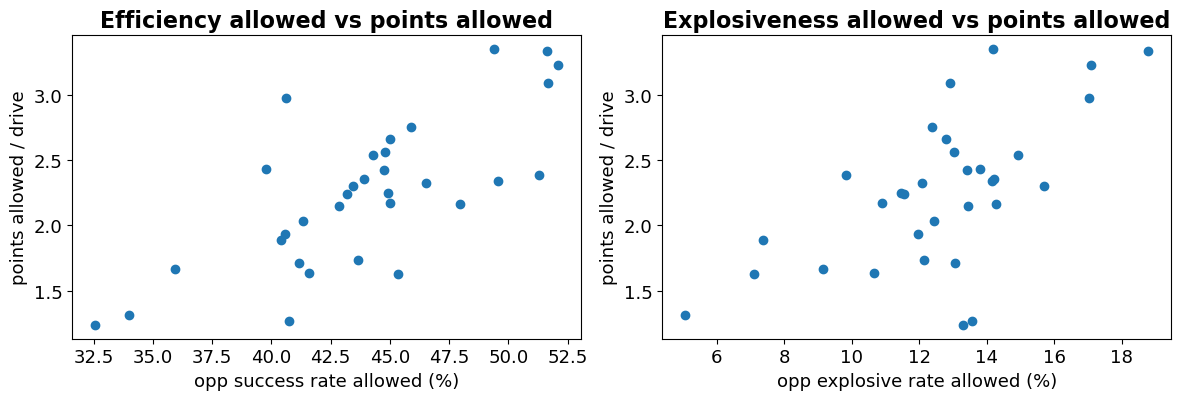

In [9]:
c_eff = dm["ppd_allowed"].corr(dm["success_rate_allowed"])
c_exp = dm["ppd_allowed"].corr(dm["explosive_rate_allowed"])
c_rz  = dm["ppd_allowed"].corr(dm["rz_rate_allowed"])
print(f"[{STAMP}]  correlation with POINTS ALLOWED per drive:")
print(f"   efficiency allowed (success rate):  {c_eff:+.2f}")
print(f"   explosiveness allowed (big plays):  {c_exp:+.2f}")
print(f"   red-zone trips allowed (finishing): {c_rz:+.2f}")
print("   (positive = allowing more of this = allowing more points)")

fig,ax=plt.subplots(1,2,figsize=(12,4.2))
ax[0].scatter(dm["success_rate_allowed"]*100, dm["ppd_allowed"])
ax[0].set_xlabel("opp success rate allowed (%)"); ax[0].set_ylabel("points allowed / drive")
ax[0].set_title("Efficiency allowed vs points allowed")
ax[1].scatter(dm["explosive_rate_allowed"]*100, dm["ppd_allowed"])
ax[1].set_xlabel("opp explosive rate allowed (%)"); ax[1].set_ylabel("points allowed / drive")
ax[1].set_title("Explosiveness allowed vs points allowed")
plt.show()

## 3. What a defense controls most (importance model)
Standardized regression of points allowed on the drive-quality traits a defense gives up. reached_20 excluded as outcome-proximate, exactly as on offense.

In [10]:
xs_full     = ["success_rate","explosive_rate","start_yardline_100","negative_plays","turnovers"]
xs_epaindep = ["explosive_rate","start_yardline_100","negative_plays","turnovers"]

# per-drive, from the DEFENSE's view: predict points the offense scored (= points allowed)
print(f"[{STAMP}]  standardized importance for POINTS ALLOWED (reached_20 excluded)")
print("(these are the drive traits the defense gave up; bigger |beta| = matters more)\n")
print("FULL model:")
print(std_betas(a, "offensive_points", xs_full).round(3).to_string())
print("\nEPA-INDEPENDENT model:")
print(std_betas(a, "offensive_points", xs_epaindep).round(3).to_string())
print("\nNote: same drives as offense, so the trait ranking matches. The DEFENSIVE story")
print("is in the team table + profiles (who allows the least), not in re-deriving this.")

[PREVIEW - not a finding]  standardized importance for POINTS ALLOWED (reached_20 excluded)
(these are the drive traits the defense gave up; bigger |beta| = matters more)

FULL model:
success_rate          0.544
start_yardline_100   -0.226
turnovers            -0.190
explosive_rate        0.143
negative_plays       -0.077

EPA-INDEPENDENT model:
explosive_rate        0.441
start_yardline_100   -0.268
turnovers            -0.252
negative_plays       -0.084

Note: same drives as offense, so the trait ranking matches. The DEFENSIVE story
is in the team table + profiles (who allows the least), not in re-deriving this.


## 4. Defensive team profiles (rank + tier)
Ranks flip vs offense: for "allowed" stats, rank 1 = fewest allowed. For takeaways/sacks, rank 1 = most.

In [11]:
N = len(dm)
prof = dm.copy()
# lower-is-better -> rank ascending (1 = best defense)
prof["r_pts"] = prof["ppd_allowed"].rank(ascending=True).astype(int)
prof["r_eff"] = prof["success_rate_allowed"].rank(ascending=True).astype(int)
prof["r_exp"] = prof["explosive_rate_allowed"].rank(ascending=True).astype(int)
prof["r_fin"] = prof["rz_rate_allowed"].rank(ascending=True).astype(int)
prof["r_fp"]  = prof["avg_start_forced"].rank(ascending=False).astype(int)  # higher = better
# higher-is-better -> rank descending
prof["r_to"]   = prof["to_forced_rate"].rank(ascending=False).astype(int)
prof["r_sack"] = prof["sack_rate"].rank(ascending=False).astype(int)

def tier(rank, n):
    if rank<=5: return "top 5 (elite)"
    if rank<=10: return "top 10 (strong)"
    if rank>n-5: return "bottom 5 (worst)"
    if rank>n-10: return "bottom 10 (weak)"
    return "middle of the pack"

def defense_profile(team):
    if team not in prof.index:
        print("no data for", team); return
    row = prof.loc[team]
    dims = [("Points allowed","r_pts"),("Efficiency allowed","r_eff"),
            ("Explosiveness allowed","r_exp"),("Finishing allowed","r_fin"),
            ("Field position forced","r_fp"),("Takeaways","r_to"),("Pass rush (sacks)","r_sack")]
    print(f"=== {team} DEFENSE  [{STAMP}] ===")
    print(f"points allowed per drive: {row['ppd_allowed']:.2f}  (rank {int(row['r_pts'])} of {N})\n")
    for name,rc in dims:
        r=int(row[rc])
        if PREVIEW:
            print(f"{name:24s}: {'above' if r<=N/2 else 'below'} average  (small sample - rank hidden)")
        else:
            print(f"{name:24s}: {r} of {N}  ({tier(r,N)})")

# example - change to any team
defense_profile(prof.index[0])

=== ARI DEFENSE  [PREVIEW - not a finding] ===
points allowed per drive: 2.43  (rank 23 of 32)

Points allowed          : below average  (small sample - rank hidden)
Efficiency allowed      : above average  (small sample - rank hidden)
Explosiveness allowed   : below average  (small sample - rank hidden)
Finishing allowed       : below average  (small sample - rank hidden)
Field position forced   : below average  (small sample - rank hidden)
Takeaways               : above average  (small sample - rank hidden)
Pass rush (sacks)       : above average  (small sample - rank hidden)


## 5. Defensive over/underperformance
Does a defense allow more or fewer points than the drives it faced predict? Same engine as offense, from the other side. Fewer-than-expected = "bend but don't break" or good red-zone D (or luck); more-than-expected = gave up more than the drives suggest.

In [12]:
xs=["success_rate","explosive_rate","start_yardline_100","negative_plays","turnovers"]
pred = ols_predict(a, "offensive_points", xs)
pred["defteam"] = a.loc[pred.index, "defteam"]
dgap = pred.groupby("defteam").agg(actual_allowed=("offensive_points","mean"),
                                   expected_allowed=("pred","mean"))
# for a DEFENSE, allowing FEWER than expected is good, so gap = expected - actual
dgap["gap"] = (dgap["expected_allowed"] - dgap["actual_allowed"]).round(2)
best = dgap.sort_values("gap", ascending=False)
print(f"[{STAMP}]  allowed FEWER points than the drives faced predict (best 3):")
print(best.head(3).round(2).to_string())
print(f"\n[{STAMP}]  allowed MORE than predicted (bottom 3):")
print(best.tail(3).round(2).to_string())
print("\n+ gap = stingier than the drives suggest (good/lucky). - gap = leakier than expected.")

[PREVIEW - not a finding]  allowed FEWER points than the drives faced predict (best 3):
         actual_allowed  expected_allowed   gap
defteam                                        
JAX                1.27              1.93  0.67
PIT                2.16              2.70  0.53
SF                 1.62              2.16  0.53

[PREVIEW - not a finding]  allowed MORE than predicted (bottom 3):
         actual_allowed  expected_allowed   gap
defteam                                        
WAS                2.66              2.26 -0.40
DET                3.33              2.86 -0.47
TEN                2.75              2.21 -0.54

+ gap = stingier than the drives suggest (good/lucky). - gap = leakier than expected.


## Reading the defensive side

- **Points allowed per drive** is the headline: lower is better, and it's the mirror of offensive points per drive.
- The trait ranking in Section 3 is identical to offense (same drives), so the *defensive* insight lives in the **team table and profiles**: which defenses give up the least efficiency, the fewest big plays, the fewest red-zone trips.
- Same gate, same caveats: nobody's rankable until 40 drives faced, everything is PREVIEW until then.
- **Field position forced** is partly special teams, not the defense itself, so read that row with a grain of salt.

Next: once both sides exist and the gate opens (~Week 5), offense ratings + defense ratings are what opponent adjustment and the predictive model are built from.